# Optics matching with Bayesian optimization

We first track a beam through a FODO lattice, then use **BoTorch** to find periodic Twiss parameters. Each objective evaluation runs RF-Track; a Gaussian process learns from those evaluations and proposes the next trial.

This notebook requires RF-Track, NumPy, Matplotlib, PyTorch, and BoTorch (which installs GPyTorch). If needed, run `%pip install botorch` in a separate notebook cell, then restart the kernel. See the [BoTorch getting-started example](https://botorch.org/) for the underlying API.

In [1]:
import RF_Track as rft
import numpy as np
import matplotlib.pyplot as plt

## Bunch parameters

In [2]:
# Bunch parameters
mass = rft.electronmass # MeV/c^2
charge = -1 # single-particle charge, in units of e
population = 1*rft.nC # number of real particles per bunch
Pc = 5 # reference momentum, MeV/c
P_Q = Pc / charge # MV/c, reference rigidity

## FODO cell parameters

In [3]:
# FODO cell parameters
Lcell = 2 # m
Lquad = 0.2 # m
Ldrift = Lcell/2 - Lquad # m

mu = np.deg2rad(90) # deg
k1L = np.sin(mu/2) / (Lcell/4) # 1/m

strength = k1L * P_Q # MeV/m

In [4]:
print(strength)

-7.071067811865475


## Define the elements

In [5]:
# Half a focusing quadrupole

Qf = rft.Quadrupole(Lquad/2, strength/2)
Qf.set_tt_nsteps(10)

# A full, defocusing, quadrupole
QD = rft.Quadrupole(Lquad, -strength)
QD.set_tt_nsteps(20)

# The Drift
Dr = rft.Drift(Ldrift)
Dr.set_tt_nsteps(100)

# Define a lattice with 10 FODO cells

In [6]:
# Define the FODO cell
FODO = rft.Lattice()
FODO.append(Qf)
FODO.append(Dr)
FODO.append(QD)
FODO.append(Dr)
FODO.append(Qf)

# Create the full lattice by repeating the FODO cell 10 times
L = rft.Lattice()
for _ in range(10):
    L.append(FODO)

# ...and a bunch

In [7]:
# Define Twiss parameters
Twiss = rft.Bunch6d_twiss()
Twiss.emitt_x = 0.001 # mm.mrad, normalized emittances
Twiss.emitt_y = 0.001 # mm.mrad
Twiss.alpha_x = 0.0
Twiss.alpha_y = 0.0
Twiss.beta_x = Lcell * (1 + np.sin(mu/2)) / np.sin(mu) # m
Twiss.beta_y = Lcell * (1 - np.sin(mu/2)) / np.sin(mu) # m

# Create the bunch
B0 = rft.Bunch6d_QR (mass, population, charge, Pc, Twiss, 1000)

In [8]:
print(Twiss.beta_x)
print(Twiss.beta_y)

3.414213562373095
0.5857864376269051


# Then, we can perform tracking

In [9]:
L.set_tt_nsteps(1000)
B1 = L.track(B0)

We can query the lattice to obtain, for example, the Twiss parameters and emittance.

In [10]:
T = L.get_transport_table('%S %beta_x %beta_y %emitt_x %emitt_y %sigma_x %sigma_y');

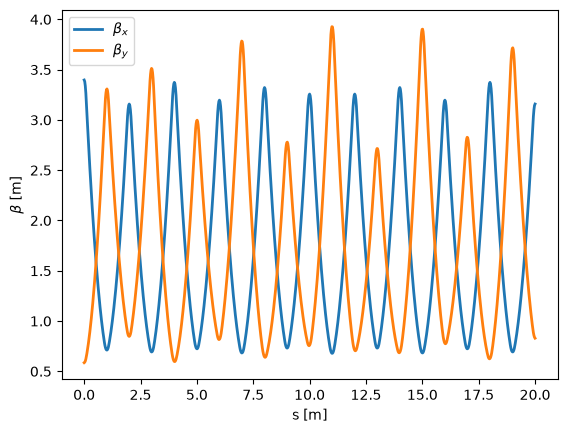

In [11]:
plt.plot(T[:,0], T[:,1], linewidth=2, label=r'$\beta_x$')
plt.plot(T[:,0], T[:,2], linewidth=2, label=r'$\beta_y$')
plt.legend()
plt.xlabel('s [m]')
plt.ylabel(r'$\beta$ [m]')
plt.show()

# Now we can match the Twiss parameters to be periodic
## Start with defining a merit function
This function returns zero when the initial and final beta functions are equal and the initial and final alpha functions are equal:
\begin{align*}
\chi^{2}= & \left(\beta_{x,\text{ final}}-\beta_{x,\text{ initial}}\right)^{2}+\cdots\\
 & \left(\beta_{y,\text{ final}}-\beta_{y,\text{ initial}}\right)^{2}+\cdots\\
 & \left(\alpha_{x,\text{ final}}-\alpha_{x,\text{ initial}}\right)^{2}+\cdots\\
 & \left(\alpha_{y,\text{ final}}-\alpha_{y,\text{ initial}}\right)^{2}
\end{align*}

We keep this simple merit function for continuity with the optics example. It combines beta differences in metres with dimensionless alpha differences, so its relative weights implicitly depend on that choice of units. A production matching problem should scale each residual by a chosen tolerance.

In [12]:
def match_Twiss(twiss, FODO):

    beta_x = twiss[0] # m
    beta_y = twiss[1] # m
    alpha_x = twiss[2]
    alpha_y = twiss[3]
    
    # Create a bunch with initial beta_x and beta_y from 'twiss'
    Twiss = rft.Bunch6d_twiss()
    Twiss.emitt_x = 0.001 # mm.mrad, normalized emittances
    Twiss.emitt_y = 0.001 # mm.mrad
    Twiss.beta_x = beta_x # m
    Twiss.beta_y = beta_y # m
    Twiss.alpha_x = alpha_x #
    Twiss.alpha_y = alpha_y #
    
    # Create the bunch
    B0 = rft.Bunch6d_QR (mass, population, charge, Pc, Twiss, 1000)
    
    # Perform tracking
    B1 = FODO.track(B0)
    I1 = B1.get_info()

    # Compute the merit function
    M = ((I1.beta_x - beta_x) ** 2 +
         (I1.beta_y - beta_y) ** 2 +
         (I1.alpha_x - alpha_x) ** 2 +
         (I1.alpha_y - alpha_y) ** 2)

    return M

## Bayesian optimization: learn, propose, evaluate

BoTorch maximizes an objective. We therefore model $y=-\log_{10}(M+10^{-8})$, where $M$ is the matching merit above. This monotonic transformation preserves the optimum and compresses large mismatches while resolving small merits (the offset keeps zero merit finite); a larger score means a smaller merit.

The four inputs are $(\beta_x,\beta_y,\alpha_x,\alpha_y)$. We search a box around the thin-lens estimate, with strictly positive beta values. These bounds express prior physical knowledge, and may need widening for a different lattice. Inputs are normalized to $[0,1]^4$ and scores are standardized before fitting the Gaussian process.

We seed the data with the thin-lens estimate and Sobol points that cover the box. At each iteration, **log expected improvement** balances exploring uncertain regions and improving the best observed score. Only the proposed point is evaluated with RF-Track. BoTorch may use SciPy internally to fit the model or optimize the acquisition function; it no longer minimizes the tracking merit directly.

In [13]:
import torch
from botorch.models import SingleTaskGP
from botorch.models.transforms.outcome import Standardize
from botorch.fit import fit_gpytorch_mll
from botorch.acquisition.analytic import LogExpectedImprovement
from botorch.optim import optimize_acqf
from botorch.utils.transforms import normalize, unnormalize
from gpytorch.mlls import ExactMarginalLogLikelihood

# Double precision is recommended for Gaussian processes; RF-Track runs on CPU.
dtype = torch.double
device = torch.device("cpu")
seed = 42
torch.manual_seed(seed)

# Columns: beta_x [m], beta_y [m], alpha_x, alpha_y.
bounds = torch.tensor([[2.5, 0.4, -0.3, -0.3],
                       [4.5, 1.0,  0.3,  0.3]], dtype=dtype, device=device)
unit_bounds = torch.stack([torch.zeros(4), torch.ones(4)]).to(bounds)
initial_guess = torch.tensor([
    Lcell * (1 + np.sin(mu/2)) / np.sin(mu),
    Lcell * (1 - np.sin(mu/2)) / np.sin(mu),
    0.0, 0.0
], dtype=dtype, device=device)
assert torch.all((initial_guess >= bounds[0]) & (initial_guess <= bounds[1]))

n_initial = 16  # includes the thin-lens estimate
n_iterations = 80  # one new RF-Track evaluation per iteration


def evaluate_merit(X):
    """Map normalized inputs (n, 4) to RF-Track merits (n, 1)."""
    physical_twiss = unnormalize(X, bounds).detach().cpu().numpy()
    values = [match_Twiss(twiss, FODO) for twiss in physical_twiss]
    if not np.all(np.isfinite(values)):
        raise ValueError("Tracking returned a non-finite merit; inspect the search bounds.")
    return torch.tensor(values, dtype=dtype, device=device).unsqueeze(-1)


sobol = torch.quasirandom.SobolEngine(dimension=4, scramble=True, seed=seed)
train_X = torch.cat([
    normalize(initial_guess, bounds).unsqueeze(0),
    sobol.draw(n_initial - 1).to(bounds)
])
train_M = evaluate_merit(train_X)
train_Y = -torch.log10(train_M + 1e-8)
print(f"Initial best merit: {train_M.min().item():.6g}")

Initial best merit: 0.135161


### Fit the model and select the next experiment

`SingleTaskGP` models the scalar score. The QR bunch construction is deterministic here; a small observation variance, fixed relative to the current score variance, provides numerical regularization, rather than representing measured tracking noise. For a stochastic beam simulation, estimate its noise or fit a noise model instead.

`LogExpectedImprovement` is the numerically stable logarithm of expected improvement. Its logarithm is distinct from the `log10` transformation of the merit above. With `q=1`, we propose one experiment at a time.

In [14]:
for iteration in range(n_iterations):
    # 1. Learn the score surface from all evaluations so far.
    model = SingleTaskGP(
        train_X, train_Y,
        train_Yvar=torch.full_like(train_Y, 1e-6 * train_Y.var().item() + 1e-8),
        outcome_transform=Standardize(m=1),
    )
    mll = ExactMarginalLogLikelihood(model.likelihood, model)
    fit_gpytorch_mll(mll)

    # 2. Find the most promising next input using the cheap surrogate.
    acquisition = LogExpectedImprovement(model, best_f=train_Y.max())
    candidate, _ = optimize_acqf(
        acquisition, bounds=unit_bounds, q=1,
        num_restarts=10, raw_samples=256,
    )
    candidate = candidate.detach()

    # 3. Run the actual tracking experiment, then append its result.
    new_M = evaluate_merit(candidate)
    train_X = torch.cat([train_X, candidate])
    train_M = torch.cat([train_M, new_M])
    train_Y = -torch.log10(train_M + 1e-8)
    if (iteration + 1) % 10 == 0:
        print(f"Iteration {iteration + 1:2d}: best merit = {train_M.min().item():.6g}")

# Use the best point actually tracked, rather than the surrogate's prediction.
best_index = train_M.argmin().item()
matched_twiss = unnormalize(train_X[best_index], bounds).cpu().numpy()
initial_merit = train_M[0].item()
matched_merit = train_M[best_index].item()
print("Matched [beta_x, beta_y, alpha_x, alpha_y]:", matched_twiss)
print(f"Merit: {initial_merit:.6g} -> {matched_merit:.6g}")
print(f"Total tracking evaluations: {len(train_M)}")

Iteration 10: best merit = 0.0170793
Iteration 20: best merit = 0.00887206
Iteration 30: best merit = 0.00690906
Iteration 40: best merit = 0.00690906
Iteration 50: best merit = 0.00248099
Iteration 60: best merit = 0.000184423
Iteration 70: best merit = 0.000184423
Iteration 80: best merit = 0.000184423
Matched [beta_x, beta_y, alpha_x, alpha_y]: [ 3.27600796e+00  7.03824011e-01 -1.22684202e-03  6.96185391e-03]
Merit: 0.135161 -> 0.000184423
Total tracking evaluations: 96


### Inspect progress and periodicity

A fixed evaluation budget is a stopping rule, not a convergence guarantee. Inspect the best observed merit and the one-cell residuals, then check the beta functions through all ten cells below. Bayesian optimization is useful for expensive black-box objectives; this small smooth matching problem also provides a simple setting in which to learn its components.

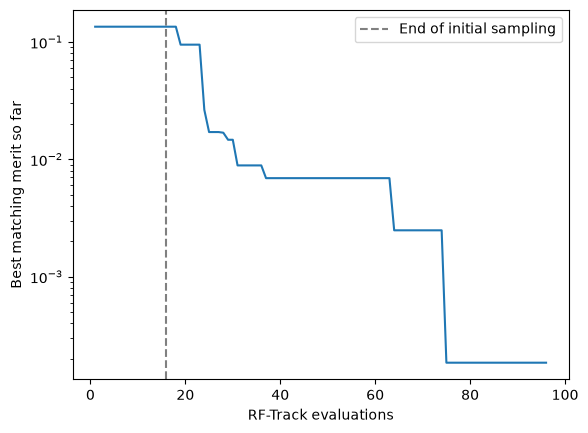

In [15]:
merit_history = train_M.squeeze(-1).cpu().numpy()
plt.semilogy(np.arange(1, len(merit_history) + 1),
             np.maximum(np.minimum.accumulate(merit_history), 1e-16))
plt.axvline(n_initial, color="grey", linestyle="--", label="End of initial sampling")
plt.xlabel("RF-Track evaluations")
plt.ylabel("Best matching merit so far")
plt.legend()
plt.show()

Let's create a beam with the best observed Twiss parameters

In [16]:
Twiss.beta_x = matched_twiss[0]
Twiss.beta_y = matched_twiss[1]
Twiss.alpha_x = matched_twiss[2]
Twiss.alpha_y = matched_twiss[3]

# Create the bunch
B0 = rft.Bunch6d_QR (mass, population, charge, Pc, Twiss, 1000)

In [17]:
# A periodic beam has the same Twiss parameters after one complete cell.
matched_info = FODO.track(B0).get_info()
final_twiss = np.array([matched_info.beta_x, matched_info.beta_y,
                        matched_info.alpha_x, matched_info.alpha_y])
for name, start, end in zip(["beta_x [m]", "beta_y [m]", "alpha_x", "alpha_y"],
                            matched_twiss, final_twiss):
    print(f"{name:12s}: initial={start: .6f}, final={end: .6f}, residual={end-start: .3e}")

beta_x [m]  : initial= 3.276008, final= 3.287267, residual= 1.126e-02
beta_y [m]  : initial= 0.703824, final= 0.708236, residual= 4.412e-03
alpha_x     : initial=-0.001227, final= 0.003590, residual= 4.817e-03
alpha_y     : initial= 0.006962, final= 0.010834, residual= 3.872e-03


In [18]:
B1 = L.track(B0)

In [19]:
T = L.get_transport_table('%S %beta_x %beta_y %emitt_x %emitt_y %sigma_x %sigma_y')

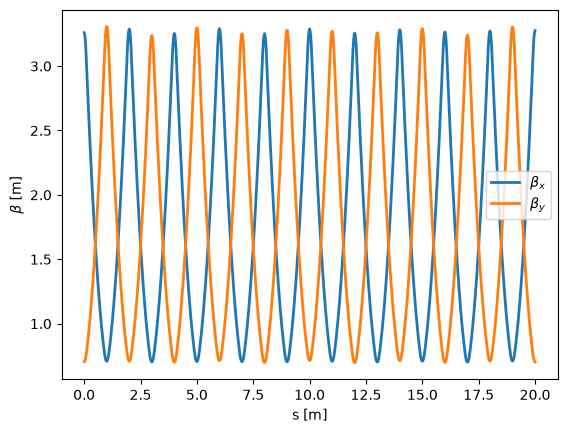

In [20]:
plt.plot(T[:,0], T[:,1], linewidth=2, label=r'$\beta_x$')
plt.plot(T[:,0], T[:,2], linewidth=2, label=r'$\beta_y$')
plt.legend()
plt.xlabel('s [m]')
plt.ylabel(r'$\beta$ [m]')
plt.show()

# Exercises

## Exercise 1 — Explore Bayesian optimization sensitivity

Repeat the optimization with different Sobol seeds, initial sample counts, and iteration budgets. Rerun from the settings cell so that each run starts with fresh data. Compare the best merit against the number of RF-Track evaluations. Does a larger budget reliably improve the match? How much do the results vary with the seed?

Widen the search bounds and compare the result at the same evaluation budget. Why does prior knowledge of a plausible optics range help? Compare modeling `-train_M` directly with `-torch.log10(train_M + 1e-8)` (change both score assignments).

Finally, add a penalty $\lambda(\beta_x^2+\beta_y^2)$ to the merit function and investigate the compromise between periodicity and beam size. Report the unpenalized periodicity residual as well as the penalized objective.

In [21]:
# Your solution